# Analysis Human-Team

### Load and Import

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

# --- General libraries --------------------------------------------------
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px          # interactive world map
import plotly.graph_objects as go    # confusion arcs, custom figures
from IPython.display import display
import torch

# --- Shared setup -------------------------------------------------------
from shared.data import Config, CountryMapper, OSV5MDataset, MetadataDecoder
from shared.models import (GeoCLIPModel, PredictionRunner, Segmenter, TextDetector,
                           Inpainter, fit_image, fit_mask, free_gpu_memory, get_device)
from shared.masking import MaskApplier
cfg = Config()

# --- Load groups own py files -------------------------------------------------------
# from pair_a.<file> import ...  


print("PyTorch", torch.__version__, "| CUDA build", torch.version.cuda)
device = get_device(cfg.device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    torch.cuda.reset_peak_memory_stats()
    
# ---------------- change settings here ----------------
cfg.images_per_country = 50
cfg.use_clip_baseline = False        # True -> downloads the original CLIP once (~1.7 GB)
cfg.crop_mode = "center_crop"        # "center_crop" | "pad" | "squash"
cfg.candidate_list = "v1"            # "v1" | "all_test_locations"
cfg.fill_mode = "gray"               # "gray" | "blur" | "inpaint" (inpaint downloads LaMa, ~200 MB)
cfg.batch_size = 32
cfg.num_workers = 4                  # set to 0 if image loading hangs (e.g. on Windows)
# ------------------------------------------------------

cfg.check()
cfg.show()

mapper = CountryMapper("resources/country_aliases.csv")
dataset = OSV5MDataset(cfg, mapper).load()      # no download, already on disk
decoder = MetadataDecoder()

run_name = f"streetclip_{cfg.candidate_list}_{cfg.crop_mode}"   # streetclip_v1_center_crop
preds, logits, embeds, info = PredictionRunner.load(f"results/shared/{run_name}")
preds = decoder.decode(preds)        # adds climate / land-cover / drive-side names

pilot_ids = dataset.build_pilot()    # loads the shared resources/pilot_ids.csv
print(f"{len(preds):,} predictions | {len(pilot_ids):,} pilot images | model: {info['model']}")

/home/flo/Projects/uni/2026WS/ai_and_visualisation_OpenSI/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
(null): No such file or directory


PyTorch 2.11.0+rocm7.2 | CUDA build None
GPU: AMD Radeon 8060S
seed                   42
device                 auto
data_dir               data
results_dir            results
resources_dir          resources
images_per_country     50
streetclip_model       geolocal/StreetCLIP
use_clip_baseline      False
clip_model             openai/clip-vit-large-patch14-336
prompt_template        A Street View photo in {country}.
candidate_list         v1
crop_mode              center_crop
batch_size             32
num_workers            4
half_precision         True
top_k                  10
segmentation_model     facebook/mask2former-swin-large-mapillary-vistas-semantic
fill_mode              gray
blur_radius            25
mask_dilation_px       5
num_random_controls    3
lama_url               https://github.com/enesmsahin/simple-lama-inpainting/releases/download/v0.1.0/big-lama.pt
210,122 predictions | 9,578 pilot images | model: geolocal/StreetCLIP


---

# Q1: Error structure and geography

which countries are confused, what do confused pairs share, are there attractor countries, do errors cluster geographically? 



102,525 wrong predictions out of 208,314 images


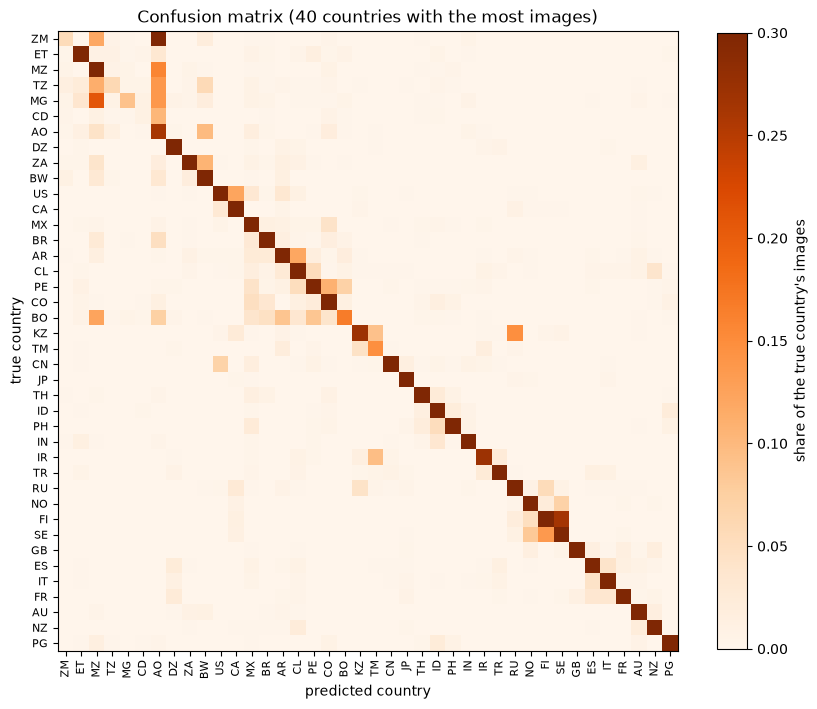

In [2]:
# Confused pairs: images from country A get predicted as country B.
countries = mapper.table                      # country info from country_aliases.csv
usable = preds[preds["representable"]]        # only images where the true country is in the candidate list
errors = usable[~usable["correct"]]
print(f"{len(errors):,} wrong predictions out of {len(usable):,} images")

# confusion matrix for the 40 countries with the most images, sorted by region
# rows are normalized over all candidates, not just the 40 shown
top = usable["country_id"].value_counts().head(40).index
top = countries.loc[top].sort_values(["world_region", "world_subregion"]).index
matrix = pd.crosstab(usable["country_id"], usable["pred_1"], normalize="index")
matrix = matrix.reindex(index=top, columns=top, fill_value=0)

plt.figure(figsize=(10, 10))
plt.imshow(matrix, cmap="Oranges", vmax=0.3)    # cap at 0.3, otherwise you only see the diagonal
plt.colorbar(label="share of the true country's images", shrink=0.8)
plt.xticks(range(len(top)), top, rotation=90, fontsize=8)
plt.yticks(range(len(top)), top, fontsize=8)
plt.xlabel("predicted country")
plt.ylabel("true country")
plt.title("Confusion matrix (40 countries with the most images)")
plt.show()

**Answer:** Most confusions happen inside the same region. Next to the diagonal there are blocks for Africa, South America and the Nordic countries. For example Zambia is predicted as Angola more often than as Zambia, and Finland is often predicted as Sweden. There are only a few confusions between continents, for example Bolivia predicted as Mozambique.

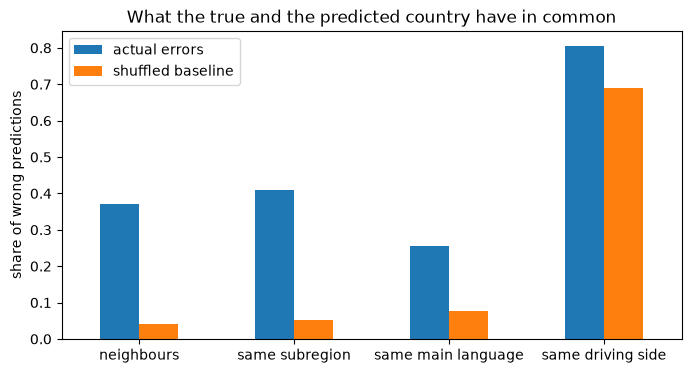

In [3]:
# what do the true and predicted country have in common (neighbours, region, language, driving side)
def shared_properties(df):
    # share of rows where true and predicted country have the same value
    true = countries.loc[df["country_id"]]
    pred = countries.loc[df["pred_1"]]
    return pd.Series({
        "neighbours": np.mean([p in n.split(";") for p, n in zip(df["pred_1"], true["neighbors"])]),
        "same subregion": np.mean(true["world_subregion"].values == pred["world_subregion"].values),
        "same main language": np.mean(true["main_language"].values == pred["main_language"].values),
        "same driving side": np.mean(true["driving_side"].values == pred["driving_side"].values),
    })

# baseline: shuffle the wrong guesses between images, drop the ones that land on the true country
shuffled = errors.assign(pred_1=errors["pred_1"].sample(frac=1, random_state=cfg.seed).values)
shuffled = shuffled[shuffled["pred_1"] != shuffled["country_id"]]

comparison = pd.DataFrame({"actual errors": shared_properties(errors),
                           "shuffled baseline": shared_properties(shuffled)})
comparison.plot.bar(rot=0, figsize=(8, 4))
plt.ylabel("share of wrong predictions")
plt.title("What the true and the predicted country have in common")
plt.show()

**Answer:** Mainly geography. About 40% of the wrong guesses are a neighbouring country or in the same subregion, compared to about 5% for the shuffled guesses. Same main language (~25% vs. ~8%) and same driving side (~80% vs. ~70%) show a smaller difference.

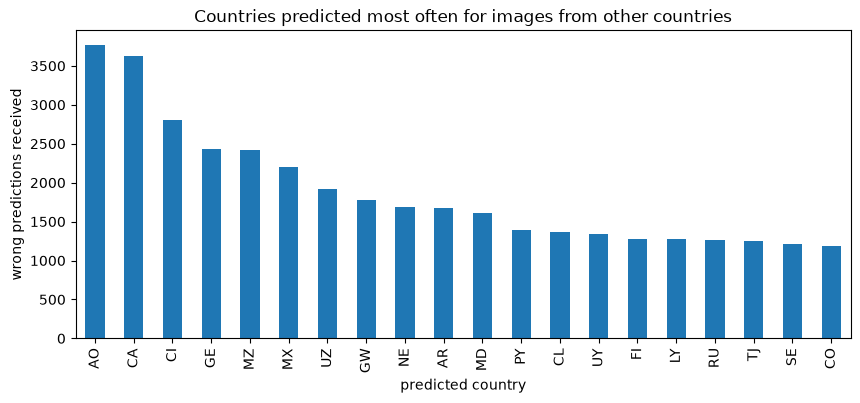

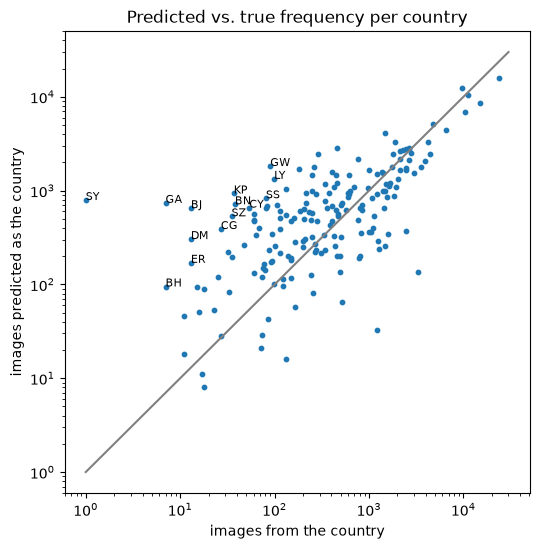

Predicted but no own images in the test set: ['AD', 'GU', 'LI', 'MC', 'MH', 'NA', 'NR', 'SC', 'SM']


In [4]:
# attractor countries = countries that get predicted a lot for images from other countries
# plot 1: countries with the most wrong predictions
errors["pred_1"].value_counts().head(20).plot.bar(figsize=(10, 4))
plt.xlabel("predicted country")
plt.ylabel("wrong predictions received")
plt.title("Countries predicted most often for images from other countries")
plt.show()

# plot 2: how often a country is predicted vs. how often it is the true country
# above the gray line = predicted more often than it appears, labels for more than 10x
# countries with 0 images don't show up on log axes, so they are printed below
counts = pd.DataFrame({"true": usable["country_id"].value_counts(),
                       "predicted": usable["pred_1"].value_counts()}).fillna(0)
plt.figure(figsize=(6, 6))
plt.scatter(counts["true"], counts["predicted"], s=10)
for country, row in counts[counts["predicted"] > 10 * counts["true"]].iterrows():
    plt.annotate(country, (row["true"], row["predicted"]), fontsize=8)
plt.plot([1, 30000], [1, 30000], color="gray")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("images from the country")
plt.ylabel("images predicted as the country")
plt.title("Predicted vs. true frequency per country")
plt.show()
print("Predicted but no own images in the test set:", counts[counts["true"] == 0].index.tolist())

**Answer:** Yes. Angola and Canada both get more than 3,500 wrong predictions, after them come Côte d'Ivoire, Georgia and Mozambique. Some small countries like Syria, Gabon and Benin are far above the diagonal. Syria for example is predicted around 800 times but has only 1 image.

In [ ]:
# do wrong guesses land close to the true country or just anywhere?
def distance_km(lat1, lon1, lat2, lon2):
    # haversine distance in km
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

def distance_to_guess(df):
    # distance from photo location to the centre of the predicted country
    guess = countries.loc[df["pred_1"]]
    return distance_km(df["latitude"].values, df["longitude"].values,
                       guess["center_lat"].values, guess["center_lng"].values)

# distance of wrong guesses
distances = distance_to_guess(errors)
plt.figure(figsize=(8, 4))
plt.hist(distances, bins=np.arange(0, 20001, 500))
plt.xlabel("distance from photo to centre of predicted country (km)")
plt.ylabel("wrong predictions")
plt.title("How far off are wrong guesses?")
plt.show()
print(f"median distance of wrong guesses: {np.median(distances):.0f} km")

**Answer:** Mostly close. The histogram peaks at 500-1,000 km and most wrong guesses are within about 2,500 km. There is a long tail up to 20,000 km and a small bump around 10,000 km.

--- 

# Q2  Overconfidence and training coverage

when is the model confidently wrong, and can we infer which countries were in its Street View training? 

---

# Q3  Visual clues

which elements (text, road, vegetation, sky, ...) change the prediction when hidden, and does this differ between countries? 

---

# Q4  Environment (secondary)

do accuracy and confidence vary with climate, land cover, distance to the sea, or urban vs. rural setting?

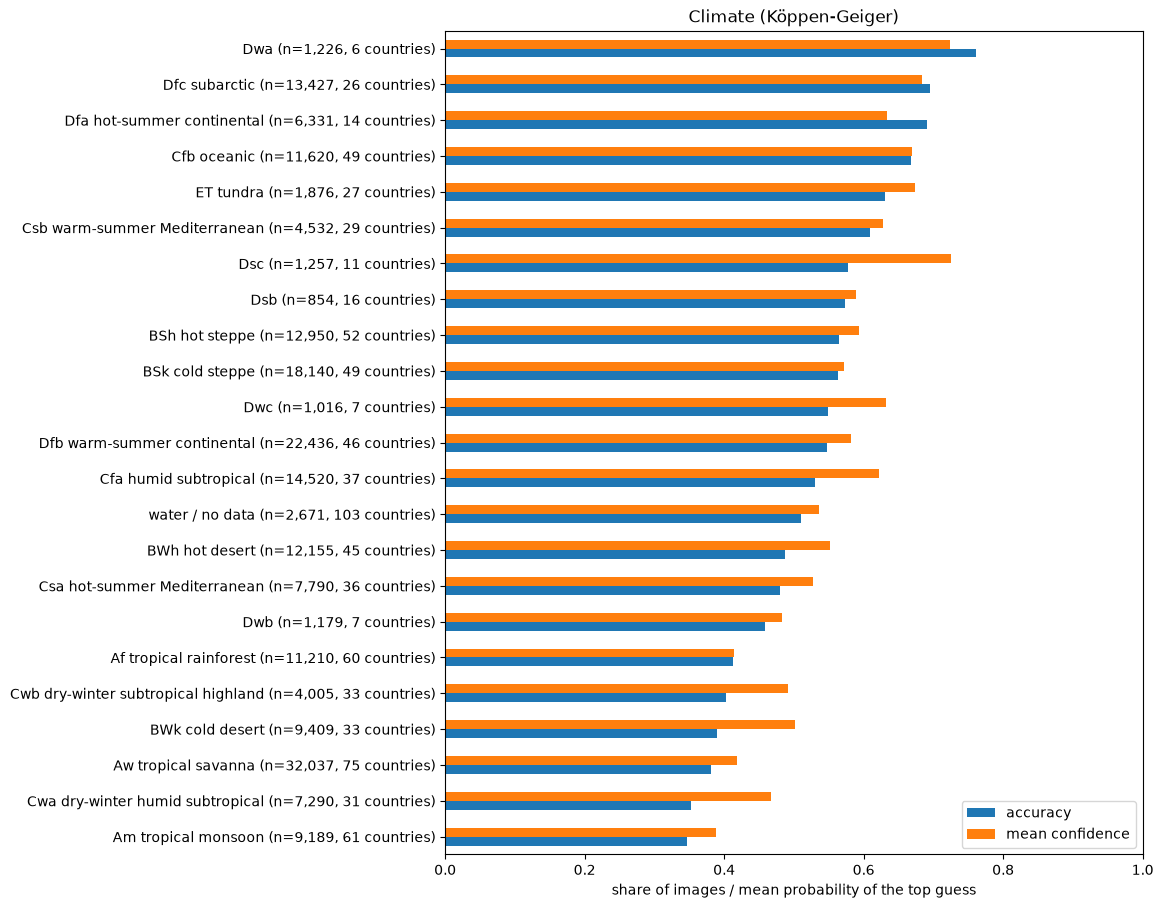

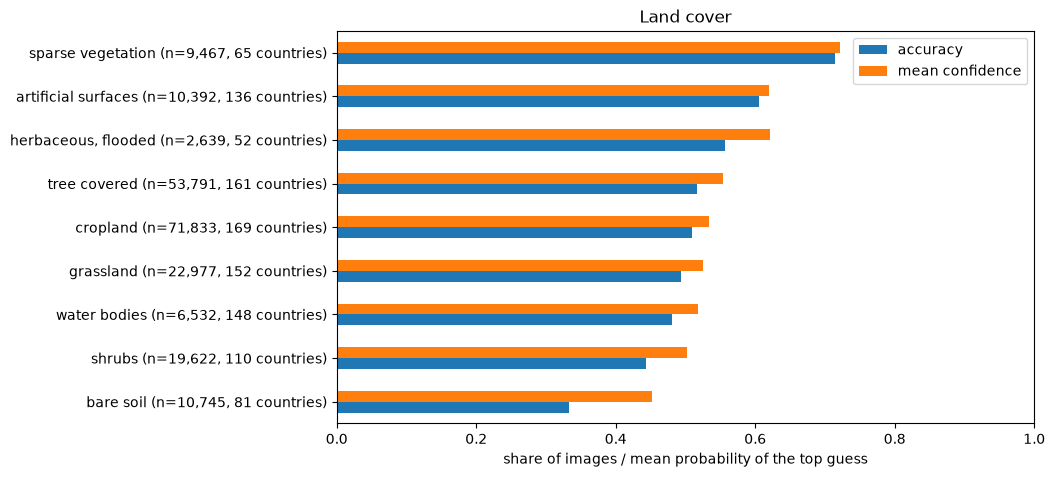

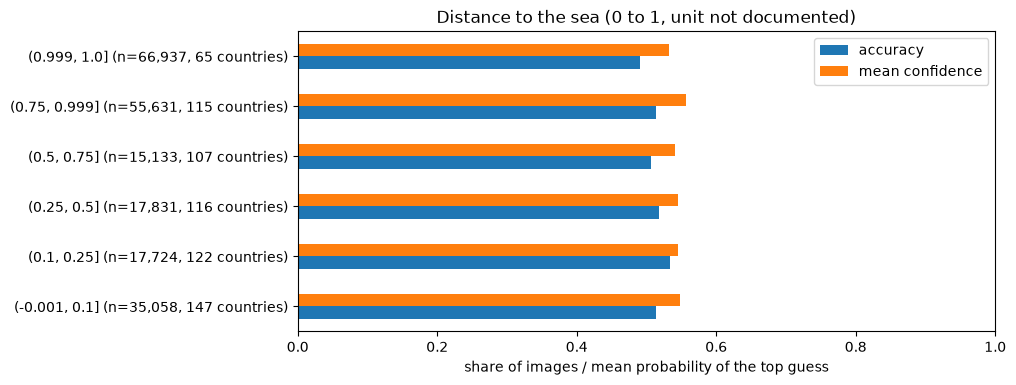

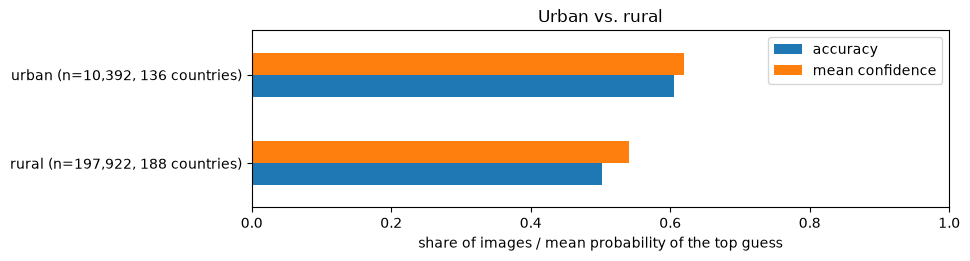

In [12]:
# accuracy and confidence per type of place instead of per country
# e.g. a desert image from Chile and one from Morocco end up in the same group
env = preds[preds["representable"]].copy()
env["correct"] = env["correct"].astype(float)
env["dist_sea_bin"] = pd.cut(env["dist_sea"], [0, 0.1, 0.25, 0.5, 0.75, 0.999, 1], include_lowest=True)
# OSV-5M has no urban/rural column, so land cover "artificial surfaces" is used as urban
env["urban_rural"] = np.where(env["land_cover_name"] == "artificial surfaces", "urban", "rural")

def by_group(column):
    # accuracy and mean confidence per group, groups with < 500 images or < 5 countries are dropped
    g = env.groupby(column, observed=True).agg(accuracy=("correct", "mean"), confidence=("prob_1", "mean"),
                                               n=("correct", "size"), countries=("country_id", "nunique"))
    g = g[(g["n"] >= 500) & (g["countries"] >= 5)]
    g.index = [f"{name} (n={n:,}, {c} countries)" for name, n, c in zip(g.index, g["n"], g["countries"])]
    return g

panels = {
    "Climate (Köppen-Geiger)": by_group("climate_name").sort_values("accuracy"),
    "Land cover": by_group("land_cover_name").sort_values("accuracy"),
    "Distance to the sea (0 to 1, unit not documented)": by_group("dist_sea_bin"),
    "Urban vs. rural": by_group("urban_rural"),
}

for title, g in panels.items():
    g[["accuracy", "confidence"]].plot.barh(figsize=(9, 1.5 + 0.4 * len(g)))
    plt.title(title)
    plt.xlim(0, 1)
    plt.xlabel("share of images / mean probability of the top guess")
    plt.legend(["accuracy", "mean confidence"])
    plt.show()

**Answer:** Yes, mainly for climate and land cover. Accuracy goes from ~35-40% in tropical climates up to ~70% in subarctic, continental and oceanic climates. For land cover it goes from ~33% on bare soil to ~70% in sparse vegetation. Urban images are easier than rural ones (~60% vs. ~50%). Distance to the sea makes almost no difference, accuracy is around 50% in every bin. Confidence is usually a bit higher than accuracy, for bare soil and cold desert by more than 10 points. Some groups only cover a few countries (e.g. Dwa with 6), so there the result could also come from those countries and not from the type of place.